# Disseny paramètric d'un ressort de vàlvula: cerca per prova i error
**Disseny i assaig de màquines** · Màster en Enginyeria Industrial (UdG)

Una molla helicoïdal de compressió manté tancada la vàlvula d'admissió d'un motor. Amb la vàlvula tancada la molla té una longitud $L_1 = 28$ mm i ha de fer una força $F_1 = 20$ N; amb la vàlvula oberta (recorregut $y_{12} = 4$ mm, longitud $L_2 = L_1 - y_{12}$) ha de fer una força $F_2 = 40$ N.

Les incògnites són la rigidesa $k$ i la longitud lliure $L_0$. Hi ha dues condicions per a dues incògnites: el problema és **determinat** i té solució analítica. Aquí es calcula i, després, es busca la mateixa solució **per prova i error**:

1. Resolució analítica del sistema d'equacions.
2. Mètode de **Montecarlo** (cerca aleatòria).
3. **Optimització** per mínims quadrats no lineals.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.optimize import least_squares

## Funcions emprades
- `molla`: forces $F_{(1)} = k\,(L_0 - L_1)$ i $F_{(2)} = k\,(L_0 - L_2)$ de la molla (llei de Hooke).
- `residus`: errors relatius de les forces, $r_1 = (F_{(1)} - F_1)/F_1$ i $r_2 = (F_{(2)} - F_2)/F_2$.
- `error_disseny`: funció objectiu $f = r_1^2 + r_2^2$, que val zero només si les dues forces són les desitjades.
- `montecarlo`: genera $n$ dissenys aleatoris i retorna el de menor error.
- `optimitzacio`: minimitza l'error amb `least_squares` i desa l'historial d'iteracions.

In [2]:
# (en Python s'han de definir abans de cridar-les; en MatLab van al final)

def molla(k, L0, L1, L2):
    """Forces de la molla a les dues posicions de funcionament (llei de Hooke).
    Accepta escalars o vectors de NumPy (k i L0 de la mateixa mida).
    Entrada: k [N/mm], L0, L1, L2 [mm]
    Sortida: forces F_1 i F_2 [N]
    """
    F_1 = k*(L0 - L1)                           # vàlvula tancada (longitud L1)
    F_2 = k*(L0 - L2)                           # vàlvula oberta (longitud L2)
    return F_1, F_2


def residus(k, L0, L1, L2, F1, F2):
    """Errors relatius de les forces respecte de les desitjades: r_1 i r_2 [-]."""
    F_1, F_2 = molla(k, L0, L1, L2)
    return (F_1 - F1)/F1, (F_2 - F2)/F2


def error_disseny(k, L0, L1, L2, F1, F2):
    """Funció objectiu: suma dels quadrats dels errors relatius, f = r_1^2 + r_2^2."""
    r_1, r_2 = residus(k, L0, L1, L2, F1, F2)
    return r_1**2 + r_2**2


def montecarlo(n, k_max, L0_max, L1, L2, F1, F2, rng):
    """Mètode de Montecarlo (Algorisme 1).
    Genera n parells (k, L0) uniformes a (0, k_max] x (L1, L0_max] i retorna
    el de menor error f.
    """
    k  = k_max*(1 - rng.random(n))                      # uniforme a (0, k_max]
    L0 = L1 + (L0_max - L1)*(1 - rng.random(n))         # uniforme a (L1, L0_max]
    f  = error_disseny(k, L0, L1, L2, F1, F2)
    i_opt = np.argmin(f)
    return dict(k=k, L0=L0, f=f, k_opt=k[i_opt], L0_opt=L0[i_opt], f_opt=f[i_opt])


def optimitzacio(x0, k_max, L0_max, L1, L2, F1, F2):
    """Optimització per mínims quadrats no lineals (Algorisme 2).
    Minimitza f = r_1^2 + r_2^2 amb 0 < k <= k_max i L1 <= L0 <= L0_max.
    Retorna el disseny òptim, el nombre d'avaluacions i l'historial d'iteracions.
    """
    n_aval = [0]                                # comptador d'avaluacions del model

    def vector_residus(x):                      # r = [r_1, r_2]
        n_aval[0] += 1
        return np.array(residus(x[0], x[1], L1, L2, F1, F2))

    limits = ([1e-3, L1], [k_max, L0_max])
    t0 = time.perf_counter()
    sol = least_squares(vector_residus, x0, bounds=limits)
    dt = (time.perf_counter() - t0)*1e3                 # ms
    n_total = n_aval[0]                         # inclou les avaluacions del jacobià
    # historial: iterat obtingut permetent 0, 1, 2, ... avaluacions
    historial = [np.array(x0, dtype=float)]
    for m in range(1, sol.nfev + 1):
        xm = least_squares(vector_residus, x0, bounds=limits, max_nfev=m).x
        if np.linalg.norm(xm - historial[-1]) > 1e-6:
            historial.append(xm)
    return dict(k_opt=sol.x[0], L0_opt=sol.x[1], f_opt=2*sol.cost, n_aval=n_total,
                n_iter=len(historial) - 1, n_f=sol.nfev, t=dt, exit=sol.success, historial=np.array(historial))

## Dades del problema
Especificacions del cas, espai de cerca i paràmetres de Montecarlo.

In [3]:
# Posicions de funcionament [mm]
L1     = 28.0       # longitud de la molla amb la vàlvula tancada
y12    = 4.0        # recorregut de la vàlvula
L2     = L1 - y12   # longitud de la molla amb la vàlvula oberta
# Forces [N]
F1     = 20.0       # força amb la vàlvula tancada
F2     = 40.0       # força amb la vàlvula oberta
# Espai de cerca
k_max  = 10.0       # N/mm, rigidesa màxima considerada
L0_max = 40.0       # mm, longitud lliure màxima considerada
# Mètode de Montecarlo
n_MC   = [10**3, 10**4, 10**5, 10**6]   # nombre de realitzacions
rng    = np.random.default_rng(2030)    # llavor fixa per reproduir els resultats

## Apartat 1): resolució analítica
Les forces que ha de fer la molla formen un sistema de dues equacions amb dues incògnites:

$$F_1 = k\,(L_0 - L_1), \qquad F_2 = k\,(L_0 - L_2)$$

Restant-les desapareix $L_0$ i s'obté $k = (F_2 - F_1)/y_{12}$. Després, $y_1 = F_1/k$ i $L_0 = L_1 + y_1$.

In [4]:
k_an  = (F2 - F1)/y12                   # rigidesa
y1_an = F1/k_an                         # deformació amb la vàlvula tancada
y2_an = F2/k_an                         # deformació amb la vàlvula oberta
L0_an = L1 + y1_an                      # longitud lliure
print(f"Solució analítica: k = {k_an:.3f} N/mm, y1 = {y1_an:.2f} mm, "
      f"y2 = {y2_an:.2f} mm, L0 = {L0_an:.3f} mm\n")

Solució analítica: k = 5.000 N/mm, y1 = 4.00 mm, y2 = 8.00 mm, L0 = 32.000 mm



Cada equació, aïllant $L_0$, és una corba al pla $k$-$L_0$: $L_0 = L_1 + F_1/k$ i $L_0 = L_2 + F_2/k$. La solució és l'únic punt on es tallen.

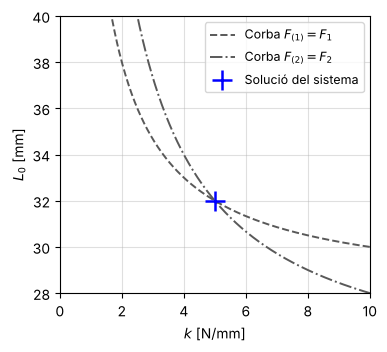

In [5]:
k_  = np.linspace(0.05, k_max, 400)
L0_F1 = L1 + F1/k_                      # corba F_1 = F1
L0_F2 = L2 + F2/k_                      # corba F_2 = F2
plt.figure(figsize=(4.0, 3.6))
plt.plot(k_, L0_F1, '--', color='0.35', linewidth=1.4, label='Corba $F_{(1)} = F_1$')
plt.plot(k_, L0_F2, '-.', color='0.35', linewidth=1.4, label='Corba $F_{(2)} = F_2$')
plt.plot(k_an, L0_an, 'b+', markersize=14, markeredgewidth=1.8, label='Solució del sistema')
plt.xlim(0, k_max); plt.ylim(L1, L0_max)
plt.xlabel('$k$ [N/mm]'); plt.ylabel('$L_0$ [mm]')
plt.legend(loc='upper right', fontsize=9)
plt.grid(True, alpha=0.4)
plt.savefig('DiAM_07a_molla_analitica_Fig0.pdf', bbox_inches='tight')
plt.show()

## Apartat 2): mètode de Montecarlo
Es generen $n$ parells $(k, L_0)$ uniformes a $(0, k_{\max}]$ i $(L_1, L_{0,\max}]$, se'n calcula l'error $f$ i es tria el de menor error. Es repeteix per a $n = 10^3, 10^4, 10^5$ i $10^6$.

In [6]:
print("Apartat 2): mètode de Montecarlo")
print(f"{'n':>9} {'k [N/mm]':>9} {'L0 [mm]':>9} {'F_1 [N]':>8} {'F_2 [N]':>8} "
      f"{'error k':>8} {'error L0':>9} {'temps [ms]':>11}")
montecarlo(1000, k_max, L0_max, L1, L2, F1, F2, rng)   # escalfament (no es compta)
res = []
for n in n_MC:
    t0 = time.perf_counter()
    R = montecarlo(n, k_max, L0_max, L1, L2, F1, F2, rng)
    dt = (time.perf_counter() - t0)*1e3                     # ms
    F_1, F_2 = molla(R['k_opt'], R['L0_opt'], L1, L2)
    err_k  = (R['k_opt'] - k_an)/k_an*100
    err_L0 = (R['L0_opt'] - L0_an)/L0_an*100
    res.append(dict(n=n, k=R['k_opt'], L0=R['L0_opt'], F_1=F_1, F_2=F_2,
                    err_k=err_k, err_L0=err_L0, t=dt))
    print(f"{n:9d} {R['k_opt']:9.3f} {R['L0_opt']:9.3f} {F_1:8.3f} {F_2:8.3f} "
          f"{err_k:7.2f}% {err_L0:8.3f}% {dt:11.1f}")
R_vis = montecarlo(10000, k_max, L0_max, L1, L2, F1, F2, rng)   # per al gràfic

Apartat 2): mètode de Montecarlo
        n  k [N/mm]   L0 [mm]  F_1 [N]  F_2 [N]  error k  error L0  temps [ms]
     1000     4.564    32.464   20.377   38.634   -8.71%    1.451%         0.9
    10000     4.940    32.044   19.974   39.733   -1.20%    0.136%         0.3
   100000     5.015    31.981   19.963   40.022    0.29%   -0.059%         7.6
  1000000     4.995    32.006   20.010   39.991   -0.10%    0.018%        52.8


Error $f$ de $n = 10^4$ dissenys aleatoris al pla $k$-$L_0$, amb les corbes de les forces desitjades. L'error és mínim on es tallen.

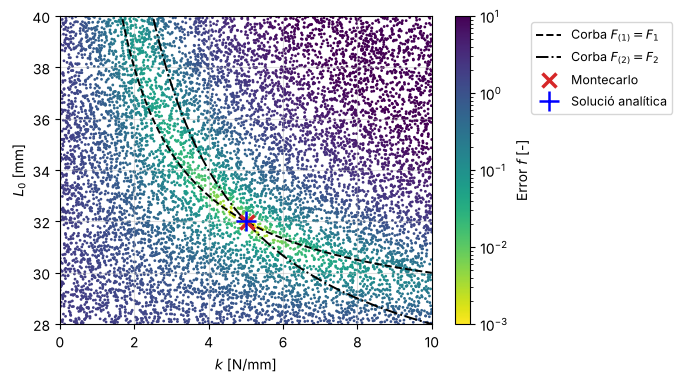

In [7]:
plt.figure(figsize=(6., 4))
sc = plt.scatter(R_vis['k'], R_vis['L0'], c=R_vis['f'], s=1, cmap='viridis_r',
                 norm=LogNorm(vmin=1e-3, vmax=10))
plt.colorbar(sc, label='Error $f$ [-]')
plt.plot(k_, L0_F1, '--', color='k', linewidth=1.4, label='Corba $F_{(1)} = F_1$')
plt.plot(k_, L0_F2, '-.', color='k', linewidth=1.4, label='Corba $F_{(2)} = F_2$')
plt.plot(R_vis['k_opt'], R_vis['L0_opt'], 'x', color='tab:red', markersize=10, markeredgewidth=2.5, label='Montecarlo')
plt.plot(k_an, L0_an, 'b+', markersize=14, markeredgewidth=1.8, label='Solució analítica')
plt.xlim(0, k_max); plt.ylim(L1, L0_max)
plt.xlabel('$k$ [N/mm]'); plt.ylabel('$L_0$ [mm]')
plt.legend(loc='upper left', bbox_to_anchor=(1.25, 1), fontsize=9)
plt.grid(True, alpha=0.4)
plt.savefig('DiAM_07a_molla_MC_Fig1.pdf', bbox_inches='tight')
plt.show()

## Apartat 3): optimització per mínims quadrats no lineals
Es minimitza $f = r_1^2 + r_2^2$ amb els límits $0 < k \le k_{\max}$ i $L_1 \le L_0 \le L_{0,\max}$. `least_squares` treballa amb els errors $r_1$ i $r_2$ per separat: a cada iteració els aproxima per funcions lineals (jacobià per diferències finites) i fa el pas que minimitza l'error dins d'una regió de confiança. El punt inicial és $(k_{\max}, L_{0,\max})$.

In [8]:
x0 = [k_max, L0_max]                      # punt inicial (no cal que sigui factible)
optimitzacio(x0, k_max, L0_max, L1, L2, F1, F2)         # escalfament (no es compta)
R_opt = optimitzacio(x0, k_max, L0_max, L1, L2, F1, F2)
dt_opt = R_opt['t']                                     # ms (només la resolució)
err_k_opt  = (R_opt['k_opt'] - k_an)/k_an*100
err_L0_opt = (R_opt['L0_opt'] - L0_an)/L0_an*100
F_1o, F_2o = molla(R_opt['k_opt'], R_opt['L0_opt'], L1, L2)
print("\nApartat 3): optimització per mínims quadrats")
print(f"  punt inicial: k = {x0[0]:.3f} N/mm, L0 = {x0[1]:.1f} mm")
print(f"  solució: k = {R_opt['k_opt']:.6f} N/mm, L0 = {R_opt['L0_opt']:.6f} mm "
      f"(errors {err_k_opt:.1e}% i {err_L0_opt:.1e}%)")
print(f"  {R_opt['n_iter']} iteracions, {R_opt['n_aval']} avaluacions del model, "
      f"{dt_opt:.1f} ms, convergència: {R_opt['exit']} (nfev = {R_opt['n_f']})")
print(f"  forces: F_1 = {F_1o:.6f} N, F_2 = {F_2o:.6f} N")
print("\n  Iteracions:")
for it, (kk, LL) in enumerate(R_opt['historial']):
    print(f"  {it:3d}  k = {kk:8.4f} N/mm  L0 = {LL:8.4f} mm  f = "
          f"{error_disseny(kk, LL, L1, L2, F1, F2):.2e}")


Apartat 3): optimització per mínims quadrats
  punt inicial: k = 10.000 N/mm, L0 = 40.0 mm
  solució: k = 5.000000 N/mm, L0 = 32.000000 mm (errors -4.3e-07% i 6.1e-08%)
  8 iteracions, 27 avaluacions del model, 2.4 ms, convergència: True (nfev = 9)
  forces: F_1 = 20.000000 N, F_2 = 40.000000 N

  Iteracions:
    0  k =  10.0000 N/mm  L0 =  40.0000 mm  f = 3.40e+01
    1  k =   7.0388 N/mm  L0 =  36.4591 mm  f = 5.33e+00
    2  k =   5.2979 N/mm  L0 =  34.3548 mm  f = 6.05e-01
    3  k =   4.4791 N/mm  L0 =  33.2799 mm  f = 3.48e-02
    4  k =   4.3863 N/mm  L0 =  32.7558 mm  f = 3.44e-03
    5  k =   4.8650 N/mm  L0 =  32.0772 mm  f = 3.77e-04
    6  k =   4.9813 N/mm  L0 =  32.0171 mm  f = 2.88e-06
    7  k =   4.9999 N/mm  L0 =  32.0001 mm  f = 4.14e-10
    8  k =   5.0000 N/mm  L0 =  32.0000 mm  f = 3.71e-18


Camí de l'optimitzador. Les corbes de punts són corbes d'error $f$ constant, que formen una vall al llarg de les dues corbes de les forces.

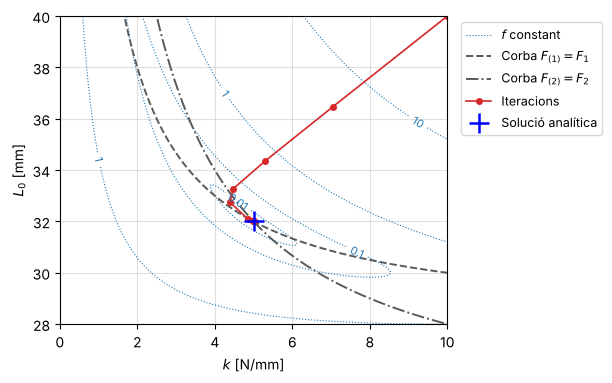

In [9]:
kk_, LL_ = np.meshgrid(np.linspace(0.05, k_max, 300), np.linspace(L1, L0_max, 300))
f_grid = error_disseny(kk_, LL_, L1, L2, F1, F2)
plt.figure(figsize=(5, 4))
cs = plt.contour(kk_, LL_, f_grid, levels=[1e-2, 1e-1, 1, 10], colors='tab:blue',
                 linewidths=0.8, linestyles=':')
plt.clabel(cs, fmt=lambda v: f'{v:g}', fontsize=8)
plt.plot([], [], ':', color='tab:blue', linewidth=0.8, label='$f$ constant')
plt.plot(k_, L0_F1, '--', color='0.35', linewidth=1.4, label='Corba $F_{(1)} = F_1$')
plt.plot(k_, L0_F2, '-.', color='0.35', linewidth=1.4, label='Corba $F_{(2)} = F_2$')
H = R_opt['historial']
plt.plot(H[:, 0], H[:, 1], 'o-', color='tab:red', markersize=4, linewidth=1.2, label='Iteracions')
plt.plot(k_an, L0_an, 'b+', markersize=14, markeredgewidth=1.8, label='Solució analítica')
plt.xlim(0, k_max); plt.ylim(L1, L0_max)
plt.xlabel('$k$ [N/mm]'); plt.ylabel('$L_0$ [mm]')
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
plt.grid(True, alpha=0.4)
plt.savefig('DiAM_07a_molla_LSQ_Fig2.pdf', bbox_inches='tight')
plt.show()